# Mouse V1 visual direction decoding

This notebook builds a baseline decoder from Allen Institute Visual Coding Neuropixels data. It selects VISp units, counts spikes during drifting-grating presentations, and evaluates a standardized multiclass logistic-regression model.

The saved 91.7% result below comes from one stratified holdout split. Use `scripts/run_extended_analysis.py` after exporting `X` and `y` for cross-validated estimates, a permutation baseline, population-size scaling, and direction-versus-orientation comparison.


In [1]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
nwb_path = "../data/session_757216464/session_757216464.nwb"

## Inspect the NWB file and stimulus table

The NWB dataset uses the field name `orientation`. In this project its eight values from 0° to 315° are treated as drifting-grating direction labels; opposite values are later collapsed with `label % 180` for an orientation-axis comparison.


In [3]:
with h5py.File(nwb_path, "r") as f:
    print(list(f.keys()))

['acquisition', 'analysis', 'file_create_date', 'general', 'identifier', 'intervals', 'processing', 'session_description', 'session_start_time', 'specifications', 'stimulus', 'timestamps_reference_time', 'units']


In [4]:
with h5py.File(nwb_path, "r") as f:
    gratings = f["intervals"]["drifting_gratings_presentations"]

    orientations = gratings["orientation"][:]
    start_times = gratings["start_time"][:]
    stop_times = gratings["stop_time"][:]

In [5]:
stimulus_df = pd.DataFrame({
    "orientation": orientations,
    "start_time": start_times,
    "stop_time": stop_times
})

In [6]:
stimulus_df.head()

,orientation,start_time,stop_time
0,90.0,1586.113585,1588.115245
1,0.0,1589.116095,1591.117775
2,90.0,1592.118605,1594.120275
3,135.0,1595.121125,1597.122785
4,315.0,1598.123625,1600.125295


In [7]:
stimulus_df.shape

(630, 3)

In [8]:
stimulus_df["orientation"].value_counts(
    dropna=False
).sort_index()

0.0      75
45.0     75
90.0     75
135.0    75
180.0    75
225.0    75
270.0    75
315.0    75
NaN      30
Name: orientation, dtype: int64

In [9]:
stimulus_df = stimulus_df.dropna(
    subset=["orientation"]
).copy()

In [10]:
stimulus_df["orientation"] = (
    stimulus_df["orientation"].astype(int)
)

In [11]:
print(stimulus_df.shape)
print(stimulus_df["orientation"].value_counts().sort_index())

(600, 3)
0      75
45     75
90     75
135    75
180    75
225    75
270    75
315    75
Name: orientation, dtype: int64


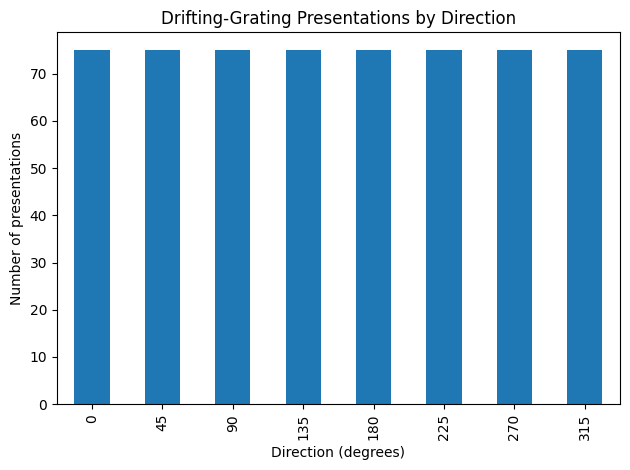

In [12]:
counts = (
    stimulus_df["orientation"]
    .value_counts()
    .sort_index()
)

counts.plot(kind="bar")

plt.xlabel("Direction (degrees)")
plt.ylabel("Number of presentations")
plt.title("Drifting-Grating Presentations by Direction")    
plt.tight_layout()
plt.show()

## Identify recorded units and their peak channels

NWB ragged arrays store every unit's spike times in one vector, with `spike_times_index` marking the endpoint for each unit.


In [13]:
with h5py.File(nwb_path, "r") as f:
    for key in f["units"].keys():
        print(key)

PT_ratio
amplitude
amplitude_cutoff
cluster_id
cumulative_drift
d_prime
firing_rate
id
isi_violations
isolation_distance
l_ratio
local_index
max_drift
nn_hit_rate
nn_miss_rate
peak_channel_id
presence_ratio
quality
recovery_slope
repolarization_slope
silhouette_score
snr
spike_amplitudes
spike_amplitudes_index
spike_times
spike_times_index
spread
velocity_above
velocity_below
waveform_duration
waveform_halfwidth
waveform_mean
waveform_mean_index


In [14]:
with h5py.File(nwb_path, "r") as f:
    units = f["units"]

    for key in units.keys():
        if "spike" in key.lower() or "channel" in key.lower() or "electrode" in key.lower():
            print(key)

peak_channel_id
spike_amplitudes
spike_amplitudes_index
spike_times
spike_times_index


In [15]:
with h5py.File(nwb_path, "r") as f:
    print("Number of units:", len(f["units"]["id"]))
    print("Spike times shape:", f["units"]["spike_times"].shape)

Number of units: 2812
Spike times shape: (136283470,)


In [16]:
with h5py.File(nwb_path, "r") as f:
    print(list(f["general"].keys()))

['devices', 'extracellular_ephys', 'institution', 'session_id', 'stimulus', 'subject']


In [17]:
with h5py.File(nwb_path, "r") as f:
    def find_structure_fields(name, obj):
        if (
            "structure" in name.lower()
            or "location" in name.lower()
            or "electrode" in name.lower()
        ):
            print(name)

    f.visititems(find_structure_fields)

general/extracellular_ephys/electrodes
general/extracellular_ephys/electrodes/filtering
general/extracellular_ephys/electrodes/group
general/extracellular_ephys/electrodes/group_name
general/extracellular_ephys/electrodes/id
general/extracellular_ephys/electrodes/imp
general/extracellular_ephys/electrodes/local_index
general/extracellular_ephys/electrodes/location
general/extracellular_ephys/electrodes/probe_horizontal_position
general/extracellular_ephys/electrodes/probe_id
general/extracellular_ephys/electrodes/probe_vertical_position
general/extracellular_ephys/electrodes/valid_data
general/extracellular_ephys/electrodes/x
general/extracellular_ephys/electrodes/y
general/extracellular_ephys/electrodes/z


In [18]:
with h5py.File(nwb_path, "r") as f:
    units = f["units"]

    unit_ids = units["id"][:]
    peak_channel_ids = units["peak_channel_id"][:]
    spike_times = units["spike_times"][:]
    spike_index = units["spike_times_index"][:]

print("Units:", len(unit_ids))
print("Spike index entries:", len(spike_index))
print("Total spikes:", len(spike_times))
print("First 5 peak channel IDs:", peak_channel_ids[:5])

Units: 2812
Spike index entries: 2812
Total spikes: 136283470
First 5 peak channel IDs: [850113094 850113094 850113094 850113094 850113104]


In [19]:
with h5py.File(nwb_path, "r") as f:
    electrodes = f["general"]["extracellular_ephys"]["electrodes"]

    electrode_ids = electrodes["id"][:]
    locations = electrodes["location"][:]

print("Number of electrodes:", len(electrode_ids))
print("First 10 IDs:", electrode_ids[:10])
print("First 10 locations:", locations[:10])

Number of electrodes: 2304
First 10 IDs: [850113794 850113796 850113800 850113804 850113808 850113810 850113814
 850113818 850113820 850113824]
First 10 locations: [b'' b'' b'' b'' b'' b'' b'' b'' b'' b'']


In [20]:
with h5py.File(nwb_path, "r") as f:
    electrodes = f["general"]["extracellular_ephys"]["electrodes"]

    for key in electrodes.keys():
        print(key)
        

filtering
group
group_name
id
imp
local_index
location
probe_horizontal_position
probe_id
probe_vertical_position
valid_data
x
y
z


In [21]:
with h5py.File(nwb_path, "r") as f:
    electrodes = f["general"]["extracellular_ephys"]["electrodes"]

    for key, value in electrodes.attrs.items():
        print(key, ":", value)

colnames : ['x' 'y' 'z' 'imp' 'location' 'filtering' 'group' 'group_name'
 'probe_vertical_position' 'probe_horizontal_position' 'probe_id'
 'local_index' 'valid_data']
description : metadata about extracellular electrodes
namespace : hdmf-common
neurodata_type : DynamicTable
object_id : 65cd9c9d-d1e4-4a2e-9ce3-571bc9dc1686


In [22]:
with h5py.File(nwb_path, "r") as f:
    def find_anatomy(name, obj):
        terms = [
            "structure",
            "acronym",
            "ccf",
            "anterior",
            "posterior",
        ]

        if any(term in name.lower() for term in terms):
            print(name)

    f.visititems(find_anatomy)

In [23]:
channels = pd.read_csv("../data/channels.csv")

print(channels.shape)
print(channels.columns.tolist())

(123224, 10)
['id', 'ecephys_probe_id', 'local_index', 'probe_horizontal_position', 'probe_vertical_position', 'anterior_posterior_ccf_coordinate', 'dorsal_ventral_ccf_coordinate', 'left_right_ccf_coordinate', 'ecephys_structure_id', 'ecephys_structure_acronym']


## Map peak channels to brain structures

Channel metadata are used to retain only units whose peak channel lies in primary visual cortex (`VISp`).


In [24]:
channels.head()

,id,ecephys_probe_id,local_index,probe_horizontal_position,probe_vertical_position,anterior_posterior_ccf_coordinate,dorsal_ventral_ccf_coordinate,left_right_ccf_coordinate,ecephys_structure_id,ecephys_structure_acronym
0,849705558,792645504,1,11,20,8165.0,3314.0,6862.0,215.0,APN
1,849705560,792645504,2,59,40,8162.0,3307.0,6866.0,215.0,APN
2,849705562,792645504,3,27,40,8160.0,3301.0,6871.0,215.0,APN
3,849705564,792645504,4,43,60,8157.0,3295.0,6875.0,215.0,APN
4,849705566,792645504,5,11,60,8155.0,3288.0,6879.0,215.0,APN


In [25]:
for col in channels.columns:
    if "structure" in col.lower() or "acronym" in col.lower():
        print(col)

ecephys_structure_id
ecephys_structure_acronym


In [26]:
channels.head(3).T

,0,1,2
id,849705558,849705560,849705562
ecephys_probe_id,792645504,792645504,792645504
local_index,1,2,3
probe_horizontal_position,11,59,27
probe_vertical_position,20,40,40
anterior_posterior_ccf_coordinate,8165.0,8162.0,8160.0
dorsal_ventral_ccf_coordinate,3314.0,3307.0,3301.0
left_right_ccf_coordinate,6862.0,6866.0,6871.0
ecephys_structure_id,215.0,215.0,215.0
ecephys_structure_acronym,APN,APN,APN


In [27]:
channels.columns.tolist()

['id',
 'ecephys_probe_id',
 'local_index',
 'probe_horizontal_position',
 'probe_vertical_position',
 'anterior_posterior_ccf_coordinate',
 'dorsal_ventral_ccf_coordinate',
 'left_right_ccf_coordinate',
 'ecephys_structure_id',
 'ecephys_structure_acronym']

In [28]:
channels.head(3).T

,0,1,2
id,849705558,849705560,849705562
ecephys_probe_id,792645504,792645504,792645504
local_index,1,2,3
probe_horizontal_position,11,59,27
probe_vertical_position,20,40,40
anterior_posterior_ccf_coordinate,8165.0,8162.0,8160.0
dorsal_ventral_ccf_coordinate,3314.0,3307.0,3301.0
left_right_ccf_coordinate,6862.0,6866.0,6871.0
ecephys_structure_id,215.0,215.0,215.0
ecephys_structure_acronym,APN,APN,APN


In [29]:
channel_to_region = dict(
    zip(
        channels["id"],
        channels["ecephys_structure_acronym"]
    )
)

In [30]:
unit_regions = np.array([
    channel_to_region.get(channel_id, "unknown")
    for channel_id in peak_channel_ids
])

In [31]:
print("Total units:", len(unit_regions))

unique_regions, counts = np.unique(
    unit_regions,
    return_counts=True
)

for region, count in zip(unique_regions, counts):
    print(region, count)

Total units: 2812
APN 133
CA1 481
CA3 93
DG 214
Eth 82
HPF 1
LGd 20
LGv 38
LP 257
MB 8
MGm 52
MRN 10
NOT 18
PO 143
ProS 66
SGN 95
SUB 116
TH 42
VIS 129
VISal 134
VISam 144
VISl 159
VISp 261
VISrl 104
unknown 12


In [32]:
visp_mask = unit_regions == "VISp"

visp_indices = np.where(visp_mask)[0]

print("VISp units:", len(visp_indices))

VISp units: 261


## Reconstruct unit spike trains


In [33]:
print("First VISp unit indices:", visp_indices[:10])
print("First VISp unit IDs:", unit_ids[visp_indices[:10]])

First VISp unit indices: [2233 2234 2235 2236 2237 2238 2239 2240 2241 2242]
First VISp unit IDs: [951800812 951800855 951800847 951800842 951800831 951800970 951800962
 951800956 951800950 951800940]


In [34]:
def get_unit_spikes(unit_index):
    end = spike_index[unit_index]

    if unit_index == 0:
        start = 0
    else:
        start = spike_index[unit_index - 1]

    return spike_times[start:end]

In [35]:
first_visp = visp_indices[0]

example_spikes = get_unit_spikes(first_visp)

print("Unit ID:", unit_ids[first_visp])
print("Number of spikes:", len(example_spikes))
print("First 10 spike times:", example_spikes[:10])

Unit ID: 951800812
Number of spikes: 14602
First 10 spike times: [ 6.34104549  7.57811265  9.05564657 12.12411446 18.37638361 24.16538592
 24.53015273 24.92155289 26.56892021 29.1410879 ]


In [36]:
stimulus_df = stimulus_df.dropna(
    subset=["orientation"]
).copy()

In [37]:
stimulus_df["orientation"] = (
    stimulus_df["orientation"].astype(int)
)

In [38]:
stimulus_df = stimulus_df.reset_index(drop=True)

In [39]:
print(stimulus_df.shape)

print(
    stimulus_df["orientation"]
    .value_counts()
    .sort_index()
)

(600, 3)
0      75
45     75
90     75
135    75
180    75
225    75
270    75
315    75
Name: orientation, dtype: int64


In [40]:
n_trials = len(stimulus_df)
n_neurons = len(visp_indices)

X = np.zeros(
    (n_trials, n_neurons),
    dtype=np.float32
)

In [41]:
for trial_idx, trial in stimulus_df.iterrows():

    start = trial["start_time"]
    stop = trial["stop_time"]

    for neuron_idx, unit_index in enumerate(visp_indices):

        neuron_spikes = get_unit_spikes(unit_index)

        X[trial_idx, neuron_idx] = np.sum(
            (neuron_spikes >= start) &
            (neuron_spikes < stop)
        )

## Build the trial-by-neuron spike-count matrix

Each row is one stimulus presentation and each column is one VISp unit. Counts use the half-open interval `[start_time, stop_time)`.


In [42]:
y = stimulus_df["orientation"].to_numpy()

In [43]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("Example neural population response:")
print(X[0, :20])

print("Corresponding direction:")
print(y[0])

X shape: (600, 261)
y shape: (600,)
Example neural population response:
[ 1. 46. 14. 27.  1.  0.  0. 14.  0.  0.  7.  1.  0.  0.  3.  1. 36.  0.
 22.  0.]
Corresponding direction:
90


In [44]:
unique, counts = np.unique(y, return_counts=True)

for orientation, count in zip(unique, counts):
    print(f"{orientation}°: {count} trials")

0°: 75 trials
45°: 75 trials
90°: 75 trials
135°: 75 trials
180°: 75 trials
225°: 75 trials
270°: 75 trials
315°: 75 trials


In [45]:
n_classes = len(unique)
chance_level = 1 / n_classes

print("Number of direction classes:", n_classes)
print("Chance accuracy:", chance_level)

Number of direction classes: 8
Chance accuracy: 0.125


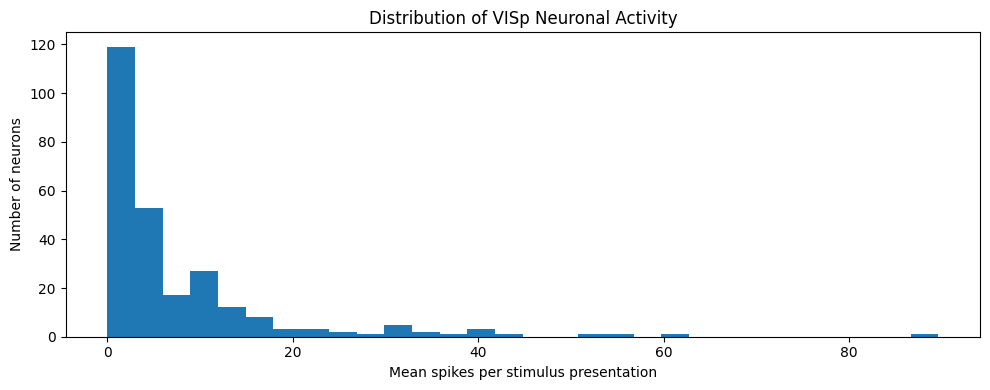

In [46]:
mean_spikes_per_neuron = X.mean(axis=0)

plt.figure(figsize=(10, 4))
plt.hist(mean_spikes_per_neuron, bins=30)

plt.xlabel("Mean spikes per stimulus presentation")
plt.ylabel("Number of neurons")
plt.title("Distribution of VISp Neuronal Activity")

plt.tight_layout()
plt.show()

In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [48]:
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (480, 261)
Test set: (120, 261)


In [49]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000
    )
)

## Single-split baseline

`StandardScaler` is inside the model pipeline, so its parameters are learned from the training data only. This section preserves the original holdout result for comparison; it is not the final validation strategy.


In [50]:
model.fit(X_train, y_train)

,steps,"[('standardscaler', ...), ('logisticregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [51]:
y_pred = model.predict(X_test)

In [52]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Decoder accuracy: {accuracy:.3f}")
print(f"Chance accuracy: {chance_level:.3f}")

Decoder accuracy: 0.917
Chance accuracy: 0.125


## Inspect baseline errors


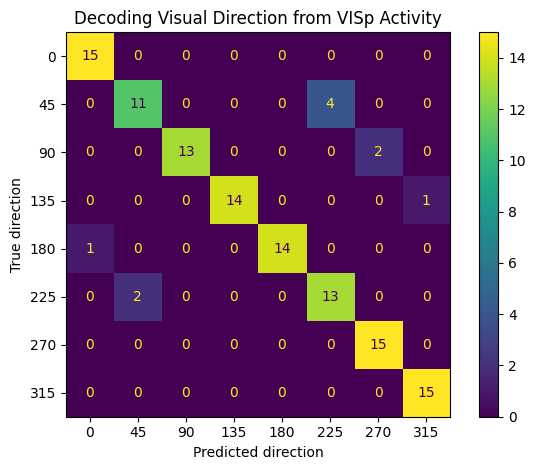

In [53]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot()

plt.xlabel("Predicted direction")
plt.ylabel("True direction")
plt.title("Decoding Visual Direction from VISp Activity")

plt.tight_layout()
plt.show()

In [54]:
import h5py
import matplotlib
import sklearn

print("h5py:", h5py.__version__)
print("matplotlib:", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)

h5py: 3.16.0
matplotlib: 3.10.8
scikit-learn: 1.7.2


In [55]:
import numpy as np
import pandas as pd
import scipy

print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("scipy:", scipy.__version__)

numpy: 1.23.5
pandas: 1.5.3
scipy: 1.10.1


## Export processed features for extended validation

This creates a compact local file containing the computed feature matrix and labels. The file is ignored by Git and can be passed to the extended-analysis script without re-reading the 3 GB NWB file.


In [ ]:
from pathlib import Path

processed_path = Path("../data/processed/spike_counts.npz")
processed_path.parent.mkdir(parents=True, exist_ok=True)
np.savez_compressed(processed_path, X=X, y=y)
print(f"Saved {X.shape[0]} trials × {X.shape[1]} neurons to {processed_path}")
